# 04 - Public vs. private schools (ENEM 2025)

**Questions answered here**
- How large is the difference between public and private school students?
- Does it repeat in every region?
- Which states have the largest and smallest differences?
- In which areas is the difference largest?
- Do public-school results get close to private-school results anywhere?

**Method notes**
- School information comes from the 2025 School Census linked by CPF (INEP read-me, pp. 7-8), restricted to final-year high school enrollments. About 61% of records have no school information, so every comparison here covers only participants with school information.
- Public = federal + state + municipal. Private = private.
- The socioeconomic questionnaire lives in a file that cannot be linked, so differences mix the effect of the school with the profile of its students. Nothing here is causal.
- State differences use the state of the school (`SG_UF_ESC`) and only states with enough private-school students.

## 1. Setup

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import stats, plots
from src.config import AREAS, RAW_DIR, SCHOOL_TYPE_NAMES
from src.load import prepare_dataset

df, school = prepare_dataset()
print(df.shape, school.shape)

(4810772, 20) (1739028, 23)


## 2. Who has school information?

In [2]:
present_lc = df[df["TP_PRESENCA_LC"] == 1]
share = present_lc["TP_DEPENDENCIA_ADM_ESC"].notna().mean()
print("Present in LC with school information:", round(share, 3))
print(
    present_lc["TP_DEPENDENCIA_ADM_ESC"]
    .map(SCHOOL_TYPE_NAMES)
    .value_counts(normalize=True)
    .round(3)
)

coverage = present_lc.groupby("SG_UF_PROVA")["TP_DEPENDENCIA_ADM_ESC"].apply(
    lambda s: s.notna().mean() * 100
)
print()
print("Coverage by state (%):")
print(coverage.round(1).sort_values().to_string())

Present in LC with school information: 0.391
TP_DEPENDENCIA_ADM_ESC
Estadual     0.753
Privada      0.190
Federal      0.052
Municipal    0.005
Name: proportion, dtype: float64

Coverage by state (%):
SG_UF_PROVA
PA    29.7
PB    30.5
AP    31.6
RN    31.8
SE    32.2
RR    32.5
BA    33.6
MA    33.7
PI    34.2
PE    35.6
RJ    35.7
DF    36.6
AC    37.6
TO    38.3
AL    38.7
MG    38.8
RS    39.0
GO    41.4
MT    41.7
MS    42.3
ES    42.8
CE    45.8
SP    46.3
RO    47.1
AM    47.9
SC    48.1
PR    48.3


## 3. Means by school type and by network

In [3]:
by_type = stats.mean_table(school, "SCHOOL_TYPE")
by_network = stats.mean_table(school, "NETWORK")
print(by_type.round(1).to_string())
print()
print(by_network.round(1).to_string())

                CN     CH     LC     MT  ESSAY_WITH_ZEROS  ESSAY_VALID_ONLY     n_LC    n_CN
SCHOOL_TYPE                                                                                 
Estadual     472.7  484.7  508.5  480.7             526.5             580.2  1017674  964740
Federal      535.7  548.6  564.2  587.0             675.8             694.9    70068   68615
Municipal    500.3  518.4  542.2  532.3             594.6             614.5     6945    6618
Privada      552.0  566.8  577.8  620.4             729.7             738.9   257179  252454

            CN     CH     LC     MT  ESSAY_WITH_ZEROS  ESSAY_VALID_ONLY     n_LC     n_CN
NETWORK                                                                                  
Private  552.0  566.8  577.8  620.4             729.7             738.9   257179   252454
Public   477.0  489.0  512.3  488.1             536.5             588.3  1094687  1039973


In [4]:
columns = AREAS + ["ESSAY_WITH_ZEROS", "ESSAY_VALID_ONLY"]
difference = by_network.loc["Private", columns] - by_network.loc["Public", columns]
print("Private minus public (points):")
print(difference.round(1))
print()
print("Private minus public (standard deviations, within each objective area):")
print(stats.gap_in_std(by_network, school).round(2))

Private minus public (points):
CN                   75.0
CH                   77.8
LC                   65.5
MT                  132.3
ESSAY_WITH_ZEROS    193.2
ESSAY_VALID_ONLY    150.7
dtype: float64

Private minus public (standard deviations, within each objective area):
CN    0.97
CH    0.95
LC    0.91
MT    1.06
dtype: float64


Scales differ by area, so the gap in points is not comparable across areas. Dividing by the standard deviation of each area gives a relative gap, which is similar across areas.

## 4. By region of the school

In [5]:
for area in ["LC", "MT"]:
    print("=====", area)
    print(stats.public_private_pivot(school, "SCHOOL_REGION", area).round(1).to_string())
    print()

===== LC
               public  private   gap  n_public  n_private
SCHOOL_REGION                                            
Centro-Oeste    514.6    580.3  65.7     89942      20056
Nordeste        497.5    569.5  72.1    401938      58134
Norte           487.5    557.5  70.0    120474      13834
Sudeste         529.2    581.9  52.6    358470     130389
Sul             533.6    582.9  49.3    123863      34766

===== MT
               public  private    gap  n_public  n_private
SCHOOL_REGION                                             
Centro-Oeste    489.4    623.5  134.1     84436      19702
Nordeste        469.3    606.6  137.3    388358      57479
Norte           453.9    574.9  121.0    113374      13579
Sudeste         510.4    628.6  118.2    339131     128002
Sul             518.4    629.3  110.9    114605      33682



## 5. By state of the school

In [6]:
state_gaps = {}
for area in ["LC", "MT"]:
    pivot = stats.public_private_pivot(school, "SG_UF_ESC", area)
    excluded = list(pivot.index[pivot["n_private"] < 1000])
    kept = stats.filter_min_private(pivot, 1000)
    state_gaps[area] = kept
    print("=====", area, "| excluded (fewer than 1,000 private-school students):", excluded)
    print(kept.round(1).sort_values("gap").to_string())
    print()

===== LC | excluded (fewer than 1,000 private-school students): ['AC', 'AP', 'RR', 'TO']
           public  private   gap  n_public  n_private
SG_UF_ESC                                            
SP          534.7    581.3  46.6    176091      75198
SC          536.7    583.7  47.0     28662       9485
PR          529.7    578.9  49.2     54018      14920
ES          525.9    575.7  49.9     22108       4101
RS          536.5    587.8  51.3     41183      10361
RN          519.2    572.3  53.1     22351       4322
RO          500.8    555.5  54.7     13548       1387
RJ          521.7    577.7  56.0     56028      27742
DF          531.9    591.0  59.2     15843       6517
MS          515.1    574.8  59.7     14687       2670
MT          506.2    566.8  60.6     18111       3457
MG          524.9    589.8  64.9    104243      23348
PE          505.3    570.7  65.4     60611      10454
PB          503.2    569.8  66.6     26794       5772
GO          511.4    579.1  67.7     41301     

### Does the minimum sample size change the extremes?

In [7]:
for area in ["LC", "MT"]:
    pivot = stats.public_private_pivot(school, "SG_UF_ESC", area)
    for minimum in [500, 1000, 2000]:
        kept = stats.filter_min_private(pivot, minimum).sort_values("gap")
        print(
            area, "| minimum", minimum, "| states:", len(kept),
            "| smallest gap:", kept.index[0], round(kept["gap"].iloc[0], 1),
            "| largest gap:", kept.index[-1], round(kept["gap"].iloc[-1], 1),
        )

LC | minimum 500 | states: 26 | smallest gap: SP 46.6 | largest gap: AM 88.4
LC | minimum 1000 | states: 23 | smallest gap: SP 46.6 | largest gap: AM 88.4
LC | minimum 2000 | states: 22 | smallest gap: SP 46.6 | largest gap: AM 88.4
MT | minimum 500 | states: 26 | smallest gap: AP 101.2 | largest gap: PI 156.8
MT | minimum 1000 | states: 23 | smallest gap: RO 103.0 | largest gap: PI 156.8
MT | minimum 2000 | states: 22 | smallest gap: SP 106.3 | largest gap: PI 156.8


### Is there a state where the public mean gets close to the private mean?
This compares state means, not individual schools.

In [8]:
kept = state_gaps["LC"]
print("Highest public mean:", kept["public"].idxmax(), round(kept["public"].max(), 1))
print("Lowest private mean:", kept["private"].idxmin(), round(kept["private"].min(), 1))
print("Smallest gap:", kept["gap"].idxmin(), round(kept["gap"].min(), 1))

Highest public mean: SC 536.7
Lowest private mean: PA 551.7
Smallest gap: SP 46.6


## 6. Charts

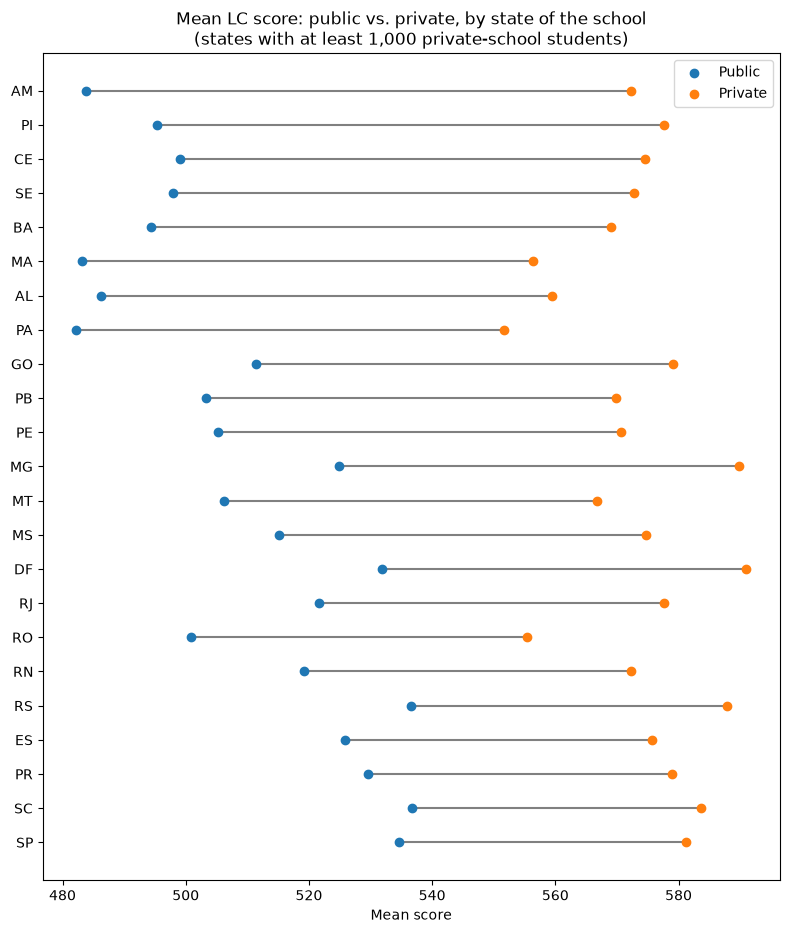

In [9]:
fig = plots.gap_dumbbell(state_gaps["LC"])
plt.gca().set_title("Mean LC score: public vs. private, by state of the school\n(states with at least 1,000 private-school students)")
plots.save_figure(fig, "lc_public_private_by_state.png")
plt.show()

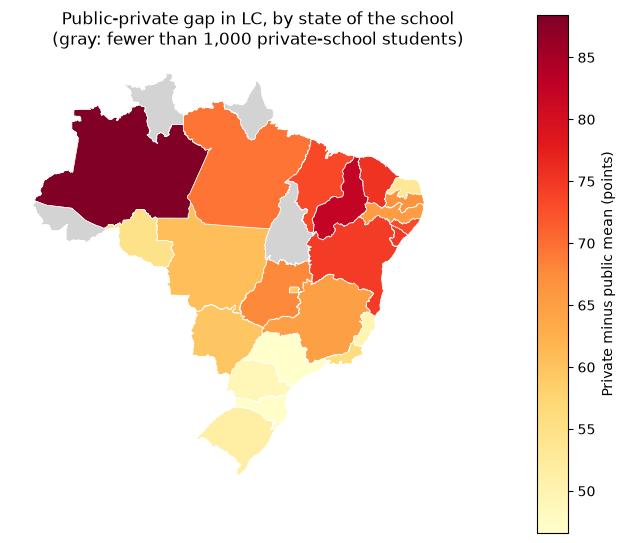

In [10]:
import geopandas as gpd

shapefiles = list(RAW_DIR.parent.glob("ibge_uf_2025/*.shp"))
if shapefiles:
    shapes = gpd.read_file(shapefiles[0])
    fig = plots.gap_map(
        shapes, state_gaps["LC"],
        "Public-private gap in LC, by state of the school\n(gray: fewer than 1,000 private-school students)",
    )
    plots.save_figure(fig, "map_lc_gap_by_state.png")
    plt.show()
else:
    print("Shapefile not found in data/raw/ibge_uf_2025")

## 7. Distributions and overlap (LC)

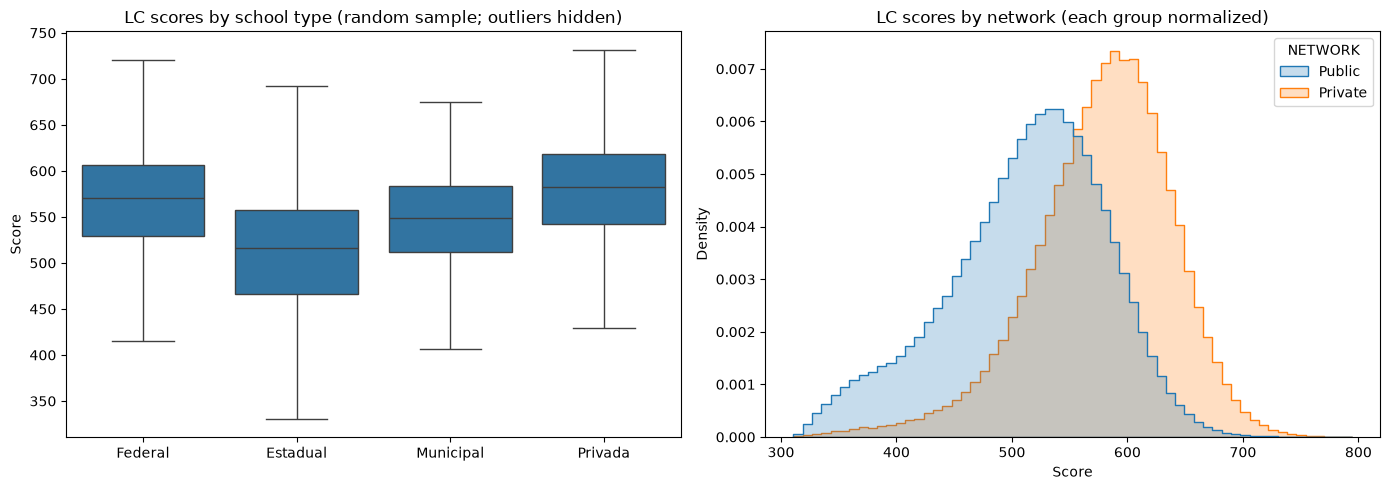

In [11]:
lc_school = school[school["TP_PRESENCA_LC"] == 1]
sample = lc_school[["SCHOOL_TYPE", "NETWORK", "NU_NOTA_LC"]].sample(n=min(300_000, len(lc_school)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(
    data=sample, x="SCHOOL_TYPE", y="NU_NOTA_LC",
    order=["Federal", "Estadual", "Municipal", "Privada"],
    showfliers=False, ax=axes[0],
)
axes[0].set_title("LC scores by school type (random sample; outliers hidden)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Score")

sns.histplot(
    data=lc_school, x="NU_NOTA_LC", hue="NETWORK", bins=60,
    stat="density", common_norm=False, element="step", ax=axes[1],
)
axes[1].set_title("LC scores by network (each group normalized)")
axes[1].set_xlabel("Score")
plt.tight_layout()
plots.save_figure(fig, "lc_school_distributions.png")
plt.show()

In [12]:
public = lc_school.loc[lc_school["NETWORK"] == "Public", "NU_NOTA_LC"]
private = lc_school.loc[lc_school["NETWORK"] == "Private", "NU_NOTA_LC"]
quantiles = [0.1, 0.25, 0.5, 0.75, 0.9]
print("Percentiles 10/25/50/75/90, public: ", public.quantile(quantiles).round(0).tolist())
print("Percentiles 10/25/50/75/90, private:", private.quantile(quantiles).round(0).tolist())
print("% of public students above the private median:", round((public > private.median()).mean() * 100, 1))
print("% of private students below the public median:", round((private < public.median()).mean() * 100, 1))

Percentiles 10/25/50/75/90, public:  [414.0, 470.0, 520.0, 561.0, 595.0]
Percentiles 10/25/50/75/90, private: [501.0, 543.0, 584.0, 619.0, 649.0]
% of public students above the private median: 14.1
% of private students below the public median: 15.4


## 8. Findings

**Observed**
- The private-school mean is higher than the public-school mean in every area, every region and every state kept in the analysis (sections 3 to 5).
- In standard-deviation units the gap is similar across the four objective areas (0.91 in LC to 1.06 in MT); in raw points it looks much larger in Mathematics because Mathematics scores are more spread out.
- Regionally, the gap in LC and MT is largest in the Northeast and smallest in the South (section 4).
- Among the public networks, federal schools are close to private ones and well above state and municipal schools (section 3 and the boxplot). Grouping them as "public" hides this.
- The distributions overlap substantially: roughly one in seven public-school students scores above the private-school median in LC (section 7).
- The essay gap is larger when invalid essays (score 0) are included (193.2 points) than for valid essays only (150.7 points).
- At the state level, the largest LC gaps are in AM (88.4) and PI (82.3) and the smallest in SP (46.6), SC (47.0) and PR (49.2). In MT the largest is PI (156.8) in every sample-size threshold tested.
- No state comes close in LC: the highest public mean (SC, 536.7) is below the lowest private mean (PA, 551.7), and even the smallest gap (SP) is about 70% of the national gap (65.5). This compares state means, not individual schools.
- In LC the smallest and largest gaps (SP and AM) do not change with the minimum sample size. In MT the smallest gap does: AP with a minimum of 500, RO with 1,000 and SP with 2,000, so it should not be reported as a single state.

**Hypotheses (not tested here)**
- Large gaps in the North and Northeast seem to come more from low public-school means (about 483 to 499 in AM, PI, CE, SE, BA, MA, AL) than from unusually high private ones (about 557 to 578).
- The larger essay gap with zeros probably reflects more invalid essays among public-school students; this was not counted directly by network here.
- Federal schools may select students through entrance exams.
- Differences in family income and parental education probably explain a large part of the gap, but this cannot be measured with the linkable data.

**What these results do not show**
- They do not show that private schools cause higher scores.
- They apply only to participants with school information (about 39% of those present).
- Municipal schools have very few cases, so conclusions about them are not reliable.
- State-level extremes with small private-school samples are fragile (see the MT example above).